# Двойной маятник при больших отклонениях

В зелёном уровне мы сравнивали численные методы при небольших углах. Теперь начнём движение из положения $\theta_1=120^\circ$, $\theta_2=-10^\circ$ с нулевыми скоростями. Посмотрим, как изменится движение, если немного сдвинуть нижний стержень.

У большого расхождения двух расчётов могут быть две причины: разные начальные условия и накопленная ошибка интегрирования. Сначала проверим уменьшение шага, затем сравним возмущённые движения и оценим, до какого времени результат устойчив к дальнейшему уточнению.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import re

plt.rcParams.update({
    "figure.dpi": 85,
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "animation.embed_limit": 80,
})

g = 9.81
m1 = m2 = 1.0
L1 = L2 = 1.0
omega0 = np.sqrt(g / L1)
T = 24.0
s0 = np.array([*np.deg2rad([120.0, -10.0]), 0.0, 0.0])


## 1. Уравнения и численное решение

Оба угла отсчитываем от вертикали вниз. Вектор состояния — $(\theta_1,\theta_2,v_1,v_2)$, где $v_i=\dot\theta_i$. Уравнения оставим такими же, как в зелёной работе:
$$
\begin{aligned}
(m_1+m_2)L_1^2\ddot\theta_1+m_2L_1L_2\cos\delta\,\ddot\theta_2
&=-m_2L_1L_2v_2^2\sin\delta-(m_1+m_2)gL_1\sin\theta_1,\\
m_2L_1L_2\cos\delta\,\ddot\theta_1+m_2L_2^2\ddot\theta_2
&=m_2L_1L_2v_1^2\sin\delta-m_2gL_2\sin\theta_2,
\end{aligned}
\qquad \delta=\theta_1-\theta_2.
$$

Используем RK4. Функция ниже может считать сразу несколько маятников с разными начальными условиями.


In [2]:
def f(s):
    theta1, theta2, v1, v2 = np.moveaxis(s, -1, 0)
    delta = theta1 - theta2
    M11 = (m1 + m2) * L1**2
    M12 = m2 * L1 * L2 * np.cos(delta)
    M22 = m2 * L2**2
    b1 = -m2 * L1 * L2 * v2**2 * np.sin(delta) - (m1 + m2) * g * L1 * np.sin(theta1)
    b2 = m2 * L1 * L2 * v1**2 * np.sin(delta) - m2 * g * L2 * np.sin(theta2)
    det = M11 * M22 - M12**2
    a1 = (M22 * b1 - M12 * b2) / det
    a2 = (M11 * b2 - M12 * b1) / det
    return np.stack((v1, v2, a1, a2), axis=-1)


def solve(initial, h, t_end=T):
    initial = np.asarray(initial, dtype=float)
    n = int(round(t_end / h))
    dt = t_end / n
    t = np.linspace(0.0, t_end, n + 1)
    trajectory = np.empty((n + 1,) + initial.shape)
    trajectory[0] = initial
    for i in range(n):
        s = trajectory[i]
        k1 = f(s)
        k2 = f(s + dt * k1 / 2)
        k3 = f(s + dt * k2 / 2)
        k4 = f(s + dt * k3)
        trajectory[i + 1] = s + dt * (k1 + 2*k2 + 2*k3 + k4) / 6
    return t, trajectory


def coordinates(s):
    theta1, theta2 = s[..., 0], s[..., 1]
    x1 = L1 * np.sin(theta1)
    y1 = -L1 * np.cos(theta1)
    x2 = x1 + L2 * np.sin(theta2)
    y2 = y1 - L2 * np.cos(theta2)
    return x1, y1, x2, y2


def energy(s):
    theta1, theta2, v1, v2 = np.moveaxis(s, -1, 0)
    kinetic = (0.5 * (m1 + m2) * L1**2 * v1**2
               + 0.5 * m2 * L2**2 * v2**2
               + m2 * L1 * L2 * v1 * v2 * np.cos(theta1 - theta2))
    potential = ((m1 + m2) * g * L1 * (1 - np.cos(theta1))
                 + m2 * g * L2 * (1 - np.cos(theta2)))
    return kinetic + potential


def distance(a, b):
    dtheta = a[..., :2] - b[..., :2]
    dtheta = np.arctan2(np.sin(dtheta), np.cos(dtheta))
    dv = (a[..., 2:] - b[..., 2:]) / omega0
    return np.sqrt(np.sum(dtheta**2 + dv**2, axis=-1))


## 2. Начальное возмущение и шаг

Изменим только второй начальный угол на $\varepsilon=10^{-3},10^{-4},10^{-5}$ рад. Это примерно $0.057^\circ$, $0.0057^\circ$ и $0.00057^\circ$. Массы, длины и начальные скорости во всех расчётах одинаковы.

Для сравнения движений используем расстояние между состояниями:
$$D(a,b)=\sqrt{\Delta\theta_1^2+\Delta\theta_2^2+
\frac{\Delta v_1^2+\Delta v_2^2}{\omega_0^2}},\qquad \omega_0=\sqrt{g/L_1}.$$
Угловые разности здесь приводим к $[-\pi,\pi]$: положения, отличающиеся на полный оборот, совпадают. Скорости учитываем, потому что при одинаковых углах движение может идти в разных направлениях. Деление на $\omega_0$ позволяет сравнивать скорости и углы в одной шкале.

Посчитаем все четыре начальных состояния с пятью шагами. Два самых мелких шага понадобятся для проверки опорного решения.


In [3]:
epsilons = np.array([0.0, 1e-3, 1e-4, 1e-5])
initials = np.tile(s0, (len(epsilons), 1))
initials[:, 1] += epsilons
steps = [0.005, 0.0025, 0.00125, 0.000625, 0.0003125]
runs = {h: solve(initials, h) for h in steps}
h_ref = steps[-1]
t_ref, reference = runs[h_ref]


def reference_on_grid(h):
    stride = int(round(h / h_ref))
    sampled = reference[::stride]
    assert len(sampled) == len(runs[h][0])
    assert np.allclose(t_ref[::stride], runs[h][0], rtol=0, atol=1e-12)
    return sampled


errors = {}
separations = {}
for h in steps:
    t, trajectory = runs[h]
    errors[h] = distance(trajectory, reference_on_grid(h))
    separations[h] = distance(trajectory[:, 1:], trajectory[:, :1])
    assert np.isfinite(trajectory).all()

E0 = energy(initials)
print("Шаг, с     max |E(t) − E(0)| / E(0), % (все 4 движения)")
for h in steps:
    E = energy(runs[h][1])
    drift = 100 * np.max(np.abs(E - E0) / E0)
    print(f"{h:9.7f}                 {drift:.6g}")


Шаг, с     max |E(t) − E(0)| / E(0), % (все 4 движения)
0.0050000                 0.000139805
0.0025000                 5.25701e-06
0.0012500                 3.94007e-07
0.0006250                 2.67129e-08
0.0003125                 1.73341e-09


## 3. Что меняется при уменьшении шага

Сначала сравним расчёты с одинаковыми начальными условиями. Слева показано отличие от решения с шагом $0.0003125$ с. Справа — изменение энергии базового маятника. Для каждой кривой ошибки берём наибольшее отличие среди четырёх начальных состояний.

Сохранение энергии полезно проверять, но само по себе оно не гарантирует точного положения маятника: ошибка движения может вырасти и при небольшом изменении энергии.


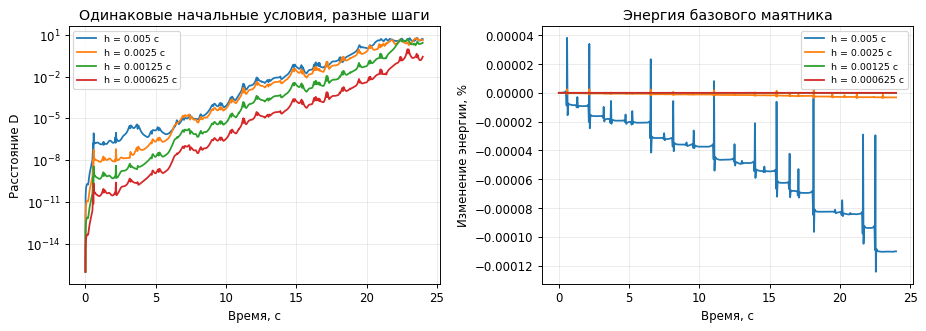

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for h in steps[:-1]:
    t, trajectory = runs[h]
    ax[0].semilogy(t, np.maximum(errors[h].max(axis=1), 1e-16), label=f"h = {h:g} с")
    drift = 100 * (energy(trajectory[:, 0]) - E0[0]) / E0[0]
    ax[1].plot(t, drift, label=f"h = {h:g} с")
ax[0].set(xlabel="Время, с", ylabel="Расстояние D", title="Одинаковые начальные условия, разные шаги")
ax[1].set(xlabel="Время, с", ylabel="Изменение энергии, %", title="Энергия базового маятника")
for a in ax:
    a.legend(fontsize=8)
fig.tight_layout()
plt.show()


## 4. Расхождение возмущённых движений

Теперь сравним разные начальные условия. На каждой панели возмущение $\varepsilon$ фиксировано, а шаг меняется. Пунктиром показана сумма отклонений базового и возмущённого решений от опорных:
$$U_h(t)=D(s_h^0,s_{\mathrm{ref}}^0)+D(s_h^\varepsilon,s_{\mathrm{ref}}^\varepsilon).$$
Она оценивает, насколько неточность двух траекторий может повлиять на их взаимное расстояние. Если пунктир сравним с самим расхождением, приписывать весь эффект начальному возмущению уже нельзя.


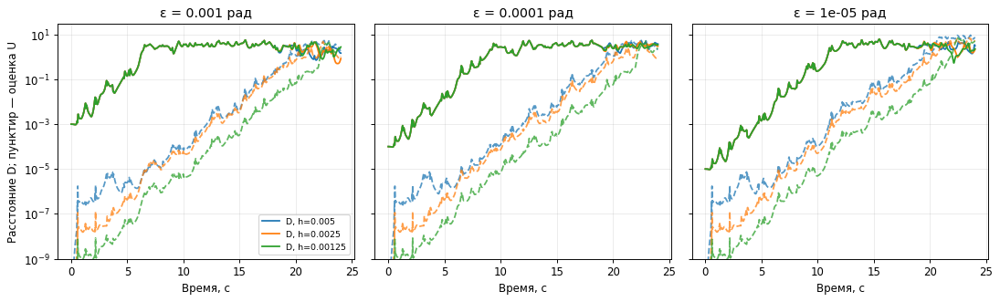

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
plot_steps = steps[:3]
colors = ["tab:blue", "tab:orange", "tab:green"]
for j, a in enumerate(ax, 1):
    for h, color in zip(plot_steps, colors):
        t, trajectory = runs[h]
        uncertainty = errors[h][:, 0] + errors[h][:, j]
        a.semilogy(t, separations[h][:, j - 1], color=color, label=f"D, h={h:g}")
        a.semilogy(t, np.maximum(uncertainty, 1e-16), "--", color=color, alpha=0.75)
    a.set(title=f"ε = {epsilons[j]:g} рад", xlabel="Время, с", ylim=(1e-9, 30))
ax[0].set_ylabel("Расстояние D; пунктир — оценка U")
ax[0].legend(fontsize=8)
fig.tight_layout()
plt.show()


## 5. До какого времени можно доверять сравнению

Зададим критерий: оценка $U_h$ должна составлять не больше 10% расстояния в опорном расчёте, а отклонение каждой траектории от опорной — не больше $0.01$ в выбранной шкале $D$. Второе условие нужно, чтобы случайное совпадение расстояний не скрыло неточность самих движений.

Проверим также опорный расчёт: отличие решений с шагами $0.000625$ и $0.0003125$ с должно давать не больше 1% расстояния между возмущёнными движениями. В таблице укажем конец непрерывного интервала от нуля, на котором выполняются все условия. После первого нарушения совпадение в отдельные более поздние моменты уже не продлевает этот интервал.

Это численная оценка для выбранных начальных условий и допусков. Решение с самым мелким шагом тоже приближённое.


In [6]:
D_ref = separations[h_ref]
fine_error = errors[steps[-2]]
trust_times = {}

print(" Шаг, с      ε=0.001 рад    ε=0.0001 рад    ε=0.00001 рад")
for h in plot_steps:
    t = runs[h][0]
    stride = int(round(h / h_ref))
    D = D_ref[::stride]
    uncertainty = errors[h][:, :1] + errors[h][:, 1:]
    fine_stride = int(round(h / steps[-2]))
    fine_uncertainty = (fine_error[:, :1] + fine_error[:, 1:])[::fine_stride]
    good = ((uncertainty <= 0.1 * D)
            & (errors[h][:, :1] <= 0.01)
            & (errors[h][:, 1:] <= 0.01)
            & (fine_uncertainty <= 0.01 * D))
    ends = []
    for j in range(3):
        bad = np.flatnonzero(~good[:, j])
        end = t[max(0, bad[0] - 1)] if bad.size else t[-1]
        trust_times[h, j + 1] = end
        ends.append(end)
    print(f"{h:9.5f}       {ends[0]:7.3f} с      {ends[1]:7.3f} с      {ends[2]:7.3f} с")

h_work = 0.00125
t_work, trajectory_work = runs[h_work]
t_common = min(trust_times[h_work, j] for j in range(1, 4))
print(f"Для h={h_work:g} с общий проверенный интервал: 0–{t_common:.2f} с.")


 Шаг, с      ε=0.001 рад    ε=0.0001 рад    ε=0.00001 рад
  0.00500        15.320 с       15.320 с        0.575 с
  0.00250        15.408 с       15.408 с       14.510 с
  0.00125        17.140 с       18.075 с       18.075 с
Для h=0.00125 с общий проверенный интервал: 0–17.14 с.


Для самого малого возмущения, $10^{-5}$ рад, шаг $0.005$ с проходит эту проверку лишь до $0.575$ с. При уменьшении шага до $0.0025$ с интервал расширяется до $14.51$ с, а при $0.00125$ с — до $18.075$ с. Оценка консервативна: в $U_h$ складываются отклонения двух траекторий, даже если часть их ошибок компенсируется при вычислении расстояния.

Для шага $0.00125$ с все три возмущения проходят проверку на общем интервале $0\leq t\leq17.14$ с. На этом участке различие движений сохраняется при уточнении расчёта. Позднее детали траекторий начинают зависеть от шага, хотя изменение энергии за все 24 с остаётся меньше $4\cdot10^{-7}\%$.



## 6. Движение маятника и графики углов

Покажем базовое движение: слева маятник со следом нижнего груза, справа оба угла. Вертикальная линия и точки на графиках соответствуют текущему положению маятника. Углы на графиках не приводим по модулю $2\pi$, чтобы были видны полные обороты.

Для анимаций используем шаг $0.00125$ с и начальный участок не длиннее 12 с, входящий в общий проверенный интервал. В ансамбле будут десять маятников с добавками к начальному углу $\theta_2$ от 0 до $10^{-3}$ рад.


In [7]:
def show_animation(animation):
    html = animation.to_jshtml(fps=20, default_mode="loop")
    html = re.sub(r'<link\b[^>]*font-awesome[^>]*>', '', html)
    icons = {
        "fa fa-minus": "−", "fa fa-plus": "+",
        "fa fa-fast-backward": "⏮", "fa fa-step-backward": "⏪",
        "fa fa-play fa-flip-horizontal": "◀", "fa fa-play": "▶",
        "fa fa-pause": "⏸", "fa fa-step-forward": "⏩",
        "fa fa-fast-forward": "⏭",
    }
    for css, symbol in icons.items():
        html = html.replace(f'<i class="{css}"></i>', f'<span>{symbol}</span>')
    display(HTML(html))


t_animation = min(12.0, np.floor(t_common * 10) / 10)
assert t_animation >= 1.0
frame_stride = int(round(0.05 / h_work))
frames = np.arange(0, int(round(t_animation / h_work)) + 1, frame_stride)
frame_t = t_work[frames]
base = trajectory_work[frames, 0]
x1, y1, x2, y2 = coordinates(base)
angles_deg = np.rad2deg(base[:, :2])

fig = plt.figure(figsize=(10, 4.8))
grid = fig.add_gridspec(2, 2, width_ratios=[1, 1.3])
pendulum_ax = fig.add_subplot(grid[:, 0])
angle_axes = [fig.add_subplot(grid[j, 1]) for j in range(2)]
pendulum_ax.set(xlim=(-2.2, 2.2), ylim=(-2.2, 2.2),
                xlabel="x, м", ylabel="y, м", title="Двойной маятник")
pendulum_ax.set_aspect("equal")
pendulum_ax.plot(0, 0, "ko", ms=4)
trail, = pendulum_ax.plot([], [], color="tab:orange", alpha=0.6, lw=1.2)
rod, = pendulum_ax.plot([], [], "o-", color="tab:blue", lw=2.5, ms=8)
clock = pendulum_ax.text(0.03, 0.95, "", transform=pendulum_ax.transAxes, va="top")
cursors, dots = [], []
for j, a in enumerate(angle_axes):
    color = ["tab:blue", "tab:orange"][j]
    a.plot(frame_t, angles_deg[:, j], color=color)
    cursors.append(a.axvline(0, color="0.4", ls="--", lw=1))
    dot, = a.plot([], [], "o", color=color, ms=6)
    dots.append(dot)
    a.set(xlim=(0, t_animation), ylabel=f"θ{j+1}, градусы")
angle_axes[0].set_title("Углы во времени")
angle_axes[1].set_xlabel("Время, с")
fig.tight_layout()


def update_single(k):
    rod.set_data([0, x1[k], x2[k]], [0, y1[k], y2[k]])
    start = max(0, k - 60)
    trail.set_data(x2[start:k+1], y2[start:k+1])
    clock.set_text(f"t = {frame_t[k]:.2f} с")
    for j in range(2):
        cursors[j].set_xdata([frame_t[k], frame_t[k]])
        dots[j].set_data([frame_t[k]], [angles_deg[k, j]])
    return rod, trail, clock, *cursors, *dots


single_animation = FuncAnimation(fig, update_single, frames=len(frames), interval=50)
plt.close(fig)
show_animation(single_animation)


## 7. Ансамбль близких движений

Все маятники подвешены в одной точке и отличаются только начальным углом нижнего стержня. Цвет каждого маятника соответствует его добавке $\varepsilon$ на шкале справа. На правой панели показано расстояние от движения с $\varepsilon=0$; чёрная точка показывает расстояние до самого удалённого из остальных маятников, а вертикальная линия отмечает текущий момент.

Для ансамбля повторим проверку шага: сравним все десять движений с расчётами при $h/2$ и $h/4$. Анимация ограничена временем, до которого тот же критерий выполнен для каждого из девяти возмущений.


In [8]:
ensemble_eps = np.linspace(0.0, 1e-3, 10)
ensemble_initials = np.tile(s0, (10, 1))
ensemble_initials[:, 1] += ensemble_eps
ensemble_runs = {}
for h in [h_work, h_work / 2, h_work / 4]:
    ensemble_runs[h] = solve(ensemble_initials, h, t_animation)

t_ensemble, ensemble = ensemble_runs[h_work]
ensemble_half = ensemble_runs[h_work / 2][1][::2]
ensemble_ref = ensemble_runs[h_work / 4][1][::4]
ensemble_error = distance(ensemble, ensemble_ref)
ensemble_fine_error = distance(ensemble_half, ensemble_ref)
ensemble_D_ref = distance(ensemble_ref[:, 1:], ensemble_ref[:, :1])
ensemble_U = ensemble_error[:, :1] + ensemble_error[:, 1:]
ensemble_U_fine = ensemble_fine_error[:, :1] + ensemble_fine_error[:, 1:]
ensemble_good = ((ensemble_U <= 0.1 * ensemble_D_ref)
                 & (ensemble_error[:, :1] <= 0.01)
                 & (ensemble_error[:, 1:] <= 0.01)
                 & (ensemble_U_fine <= 0.01 * ensemble_D_ref))
bad = np.flatnonzero(~np.all(ensemble_good, axis=1))
ensemble_end = t_ensemble[max(0, bad[0] - 1)] if bad.size else t_animation
ensemble_frames = np.arange(0, int(np.floor(ensemble_end / h_work)) + 1, frame_stride)
et = t_ensemble[ensemble_frames]
es = ensemble[ensemble_frames]
ex1, ey1, ex2, ey2 = coordinates(es)
ensemble_D = distance(es[:, 1:], es[:, :1])

fig, ax = plt.subplots(1, 2, figsize=(11, 4.8))
fig.subplots_adjust(left=0.07, right=0.82, bottom=0.14, top=0.87, wspace=0.35)
fig.suptitle("Различие только в начальном угле нижнего стержня")
cmap = plt.get_cmap("turbo")
norm = plt.Normalize(0, 1e-3)
ensemble_colors = cmap(norm(ensemble_eps))
rods = []
for j, color in enumerate(ensemble_colors):
    line, = ax[0].plot([], [], "o-", color=color, lw=1.4, ms=5, alpha=0.85)
    rods.append(line)
ax[0].plot(0, 0, "ko", ms=4, zorder=10)
ax[0].set(xlim=(-2.2, 2.2), ylim=(-2.2, 2.2), xlabel="x, м", ylabel="y, м", title="10 двойных маятников")
ax[0].set_aspect("equal")
ensemble_clock = ax[0].text(0.03, 0.95, "", transform=ax[0].transAxes, va="top")
for j in range(1, 10):
    ax[1].semilogy(et, ensemble_D[:, j - 1], color=ensemble_colors[j], lw=1)
ensemble_cursor = ax[1].axvline(0, color="0.3", ls="--", lw=1)
envelope_point, = ax[1].plot([], [], "ko", ms=5)
ax[1].set(xlim=(0, et[-1]), ylim=(1e-5, 30), xlabel="Время, с", ylabel="Расстояние от ε=0", title="Расхождение движений")
cax = fig.add_axes([0.86, 0.22, 0.018, 0.50])
bar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax)
bar.set_label("Добавка ε, рад")
bar.set_ticks([0, 0.0005, 0.001], labels=["0", "0.0005", "0.001"])


def update_ensemble(k):
    for j, line in enumerate(rods):
        line.set_data([0, ex1[k, j], ex2[k, j]], [0, ey1[k, j], ey2[k, j]])
    ensemble_clock.set_text(f"t = {et[k]:.2f} с")
    ensemble_cursor.set_xdata([et[k], et[k]])
    envelope_point.set_data([et[k]], [ensemble_D[k].max()])
    return *rods, ensemble_clock, ensemble_cursor, envelope_point


ensemble_animation = FuncAnimation(fig, update_ensemble, frames=len(et), interval=50)
plt.close(fig)
show_animation(ensemble_animation)


/tmp/ipykernel_3252676/523845715.py:48: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  bar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax)


## Вывод

При начальных углах $120^\circ$ и $-10^\circ$ даже добавка $10^{-5}$ рад ко второму углу приводит к заметному расхождению движений. Сравнение шагов показывает, что на начальном участке этот эффект связан с начальными условиями.

Для $h=0.00125$ с выбранный критерий выполнен до $17.14$ с для всех трёх возмущений. Доверять конкретным траекториям на всём интервале до 24 с оснований уже нет: ошибка интегрирования становится существенной. Обе анимации ограничены первыми 12 с; для ансамбля с десятью начальными углами этот участок дополнительно проверен уменьшением шага.

